# Fiber Photometry Analysis

This notebook demonstrates how to load, process, and visualize fiber photometry data using the refactored mimo_pack library.

## Import Libraries

Import the required libraries and functions from mimo_pack for loading Doric files, processing fiber photometry signals, and plotting.

In [1]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt 
from mimo_pack.consts import DIM_TIME
from mimo_pack.fileio.doric import load_doric
from mimo_pack.analysis.filter import lp_filter
from mimo_pack.preprocess.fiber_photometry import isosbestic_baseline, df_over_f
from mimo_pack.util.xarray import zscore
from mimo_pack.plot.timeseries import stacked_lines

## Load and Process Fiber Photometry Data

Load the raw fiber photometry data from a Doric file and apply signal correction:
- `load_doric()` returns a dict with the fiber photometry signal/isosbestic
  DataArrays plus power output, digital IO, and analog input
- `isosbestic_baseline()` regresses the isosbestic channel onto the
  low-pass filtered signal to estimate a baseline, and `df_over_f()`
  computes ΔF/F0 from the signal and that baseline, which is then z-scored

In [2]:
#data_path = os.path.join('..', 'test_data', '2025-07-18_030_M1-cM1_0000_124254167.doric')
data_path = os.path.join("D:", "Cholinergic", "project", "test_data", "2025-07-18_030_M1-cM1_0000_124254167.doric")
doric_data = load_doric(data_path)
data_xr = doric_data['fpsig']
iso_xr = doric_data['fpiso']
pow_xr = doric_data['power']
dio_xr = doric_data['dio']

data_xr_lp = lp_filter(data_xr, cutoff_freq=10)
iso_xr_lp = lp_filter(iso_xr, cutoff_freq=10)
baseline = isosbestic_baseline(data_xr_lp, iso_xr_lp)
data_fp = df_over_f(data_xr_lp, baseline)
data_fp = zscore(data_fp, dim=DIM_TIME)

## Visualize the Processed Signal

Plot the processed fiber photometry signals as stacked line plots:
- `stacked_lines()` creates a multi-channel timeseries plot with channels vertically offset for easy comparison
- The plot is zoomed to show a 500-second window from 1500-2000 seconds

(1500.0, 2000.0)

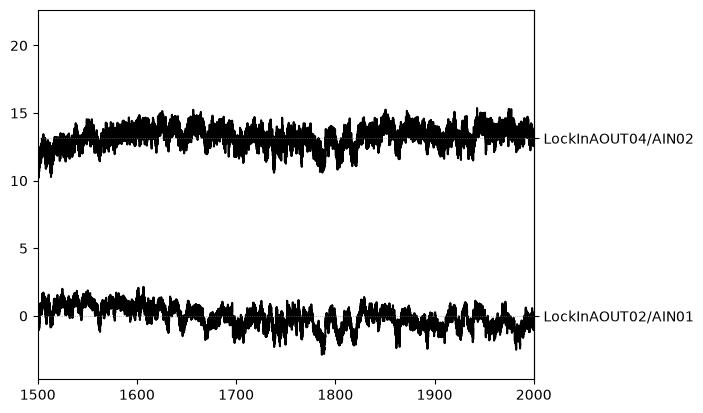

In [3]:
fig, ax = plt.subplots()
stacked_lines(data_fp, ax=ax)
ax.set_xlim(1500, 2000)